## 1. Persiapan Lingkungan dan Library

In [1]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from google.colab import files

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

## 2. Upload Data

In [2]:
up = files.upload()
nama_file = list(up.keys())[0]
print("File terbaca:", nama_file)

Saving Blank Quiz (Responses).xlsx to Blank Quiz (Responses).xlsx
File terbaca: Blank Quiz (Responses).xlsx


## 3. Membaca dan Memeriksa Data

In [3]:
df = pd.read_excel(nama_file)

data_3tia = df[df["Kelas"].astype(str).str.strip() == "3 TI A"].copy()

kolom_butir = [kolom for kolom in data_3tia.columns if "[" in str(kolom) and "]" in str(kolom)]
butir = data_3tia[kolom_butir].copy()

print("Jumlah seluruh data :", len(df))
print("Jumlah responden    :", len(butir))
print("Jumlah butir        :", butir.shape[1])
print("Data kosong         :", int(butir.isna().sum().sum()))

Jumlah seluruh data : 181
Jumlah responden    : 39
Jumlah butir        : 29
Data kosong         : 0


## 4. Mengubah Jawaban Likert Menjadi Angka

In [4]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5
}

num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")

print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
display(num.head())

Sel yang gagal dikonversi: 0


/tmp/ipykernel_624/3425187360.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.],Penggunaan AI pada tugas atau projek kuliah [Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya lebih sering menggunakan pemikiran atau jawaban yang dihasilkan AI daripada mengembangkan pemikiran sendiri.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa cemas ketika tidak dapat mengakses AI saat sedang mengerjakan tugas kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Penggunaan AI membuat saya lebih tertarik untuk mempelajari materi perkuliahan.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya tetap merasa yakin terhadap kemampuan diri sendiri pada materi kuliah meskipun menggunakan bantuan AI dalam menyelesaikan tugas kuliah.],"Kebiasaan penggunaan teknologi digital [Saya sering mengerjakan tugas kuliah sambil melakukan aktivitas lain, seperti membuka media sosial atau menonton video]",Kebiasaan penggunaan teknologi digital [Saya sering memeriksa notifikasi smartphone meskipun sedang mengerjakan tugas kuliah.],Kebiasaan penggunaan teknologi digital [aya sering menunda pengerjaan tugas karena lebih tertarik menggunakan gadget untuk kegiatan lain yang tidak berhubungan dengan tugas yang sedang saya kerjakan],"Kebiasaan penggunaan teknologi digital [Saya merasa menggunakan AI tidak membutuhkan tingkat konsentrasi yang tinggi, sehingga dapat dikerjakan bersamaan dengan kegiatan yang lain.]",Kebiasaan penggunaan teknologi digital [Saya tidak mengkhawatirkan hasil yang diberikan AI],Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.],Prokrastinasi akademik. [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik. [Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI],Prokrastinasi akademik. [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik. [Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Rsspon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Rsspon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Rsspon emosional [Saya merasa kurang puas terhadap hasil tugas yang dikerjakan karena terburu-buru mendekati deadline.],Rsspon emosional [Saya merasa lega setelah berhasil mengumpulkan tugas meskipun pengerjaannya dilakukan AI saat mendekati deadline.],Rsspon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan 

## 5. Mengelompokkan Butir per Dimensi

In [5]:
def nama_dimensi(kolom):
    nama = re.match(r"^(.*?)\s*\[", str(kolom)).group(1).strip()
    nama = re.sub(r"\s+", " ", nama).rstrip(".")
    nama = nama.replace("Rsspon emosional", "Respons emosional")
    return nama

dimensi = {}

for kolom in num.columns:
    nama = nama_dimensi(kolom)
    dimensi.setdefault(nama, []).append(kolom)

for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")

print("Jumlah dimensi:", len(dimensi))

Penggunaan AI pada tugas atau projek kuliah: 7 butir
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik: 4 butir
Respons emosional: 5 butir
Jumlah dimensi: 5


## 6. Uji Validitas

In [6]:
n = len(num)
df_bebas = n - 2
t_tabel = stats.t.ppf(0.975, df_bebas)
r_tabel = t_tabel / np.sqrt(df_bebas + t_tabel**2)

print(f"n = {n}")
print(f"df = {df_bebas}")
print(f"r tabel (α = 0,05; dua sisi) = {r_tabel:.3f}")

hasil_validitas = []

for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)

    for i, kolom in enumerate(daftar, 1):
        if x[kolom].nunique() <= 1 or total.nunique() <= 1:
            r_hitung, p_value = np.nan, np.nan
        else:
            r_hitung, p_value = stats.pearsonr(x[kolom], total)

        total_koreksi = total - x[kolom]
        if x[kolom].nunique() <= 1 or total_koreksi.nunique() <= 1:
            r_koreksi = np.nan
        else:
            r_koreksi, _ = stats.pearsonr(x[kolom], total_koreksi)

        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "Pernyataan": kolom.split("[", 1)[1].rsplit("]", 1)[0],
            "r hitung": round(r_hitung, 3) if pd.notna(r_hitung) else np.nan,
            "Corrected r": round(r_koreksi, 3) if pd.notna(r_koreksi) else np.nan,
            "p-value": round(p_value, 4) if pd.notna(p_value) else np.nan,
            "Keterangan": "Valid" if pd.notna(r_hitung) and r_hitung > r_tabel else "Tidak valid"
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
display(tabel_validitas)

n = 39
df = 37
r tabel (α = 0,05; dua sisi) = 0.316


,Dimensi,Butir,Pernyataan,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.,0.525,0.277,0.0006,Valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.,0.269,0.105,0.0972,Tidak valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek,0.643,0.379,0.0000,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.,0.669,0.397,0.0000,Valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.,0.515,0.126,0.0008,Valid
5,Penggunaan AI pada tugas atau projek kuliah,B6,Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.,0.455,0.139,0.0036,Valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.,0.016,-0.247,0.9237,Tidak valid
7,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B1,Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.,0.538,0.228,0.0004,Valid
8,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B2,aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.,0.645,0.377,0.0000,Valid
9,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B3,Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).,0.495,0.213,0.0014,Valid


## 7. Uji Reliabilitas

In [7]:
def cronbach_alpha(x):
    k = x.shape[1]
    if k < 2:
        return np.nan
    varians_total = x.sum(axis=1).var(ddof=1)
    if varians_total == 0:
        return np.nan
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / varians_total)

def kategori(alpha):
    if pd.isna(alpha):
        return "Tidak dapat dihitung"
    if alpha >= 0.90:
        return "Sangat baik"
    if alpha >= 0.80:
        return "Baik"
    if alpha >= 0.70:
        return "Reliabel"
    return "Tidak reliabel"

hasil_reliabilitas = []
alpha_dihapus = []

for nama, daftar in dimensi.items():
    x = num[daftar]
    alpha = cronbach_alpha(x)

    hasil_reliabilitas.append({
        "Dimensi": nama,
        "Jumlah butir": len(daftar),
        "Cronbach's alpha": round(alpha, 3) if pd.notna(alpha) else np.nan,
        "Kategori": kategori(alpha)
    })

    for i, kolom in enumerate(daftar, 1):
        if len(daftar) > 2:
            alpha_hapus = cronbach_alpha(x.drop(columns=kolom))
            alpha_dihapus.append({
                "Dimensi": nama,
                "Butir": f"B{i}",
                "Alpha jika dihapus": round(alpha_hapus, 3) if pd.notna(alpha_hapus) else np.nan
            })

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)

display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.370,Tidak reliabel
1,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,7,0.375,Tidak reliabel
2,Kebiasaan penggunaan teknologi digital,6,0.478,Tidak reliabel
3,Prokrastinasi akademik,4,0.863,Baik
4,Respons emosional,5,0.489,Tidak reliabel


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.275
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.362
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.193
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.171
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.367
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.348
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.513
7,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B1,0.299
8,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B2,0.200
9,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B3,0.312


## 8. Menggabungkan Hasil Validitas dan Alpha jika Butir Dihapus

In [8]:
gabung = tabel_validitas.merge(
    tabel_alpha_dihapus,
    on=["Dimensi", "Butir"],
    how="left"
)

display(gabung)

,Dimensi,Butir,Pernyataan,r hitung,Corrected r,p-value,Keterangan,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.,0.525,0.277,0.0006,Valid,0.275
1,Penggunaan AI pada tugas atau projek kuliah,B2,Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.,0.269,0.105,0.0972,Tidak valid,0.362
2,Penggunaan AI pada tugas atau projek kuliah,B3,Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek,0.643,0.379,0.0000,Valid,0.193
3,Penggunaan AI pada tugas atau projek kuliah,B4,Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.,0.669,0.397,0.0000,Valid,0.171
4,Penggunaan AI pada tugas atau projek kuliah,B5,Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.,0.515,0.126,0.0008,Valid,0.367
5,Penggunaan AI pada tugas atau projek kuliah,B6,Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.,0.455,0.139,0.0036,Valid,0.348
6,Penggunaan AI pada tugas atau projek kuliah,B7,Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.,0.016,-0.247,0.9237,Tidak valid,0.513
7,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B1,Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.,0.538,0.228,0.0004,Valid,0.299
8,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B2,aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.,0.645,0.377,0.0000,Valid,0.200
9,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B3,Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).,0.495,0.213,0.0014,Valid,0.312


## 9. Analisis Deskriptif Setiap Dimensi

In [9]:
hasil_deskriptif = []
komposisi_jawaban = []

label_skala = {
    1: "Sangat Tidak Setuju",
    2: "Tidak Setuju",
    3: "Netral",
    4: "Setuju",
    5: "Sangat Setuju"
}

for nama, daftar in dimensi.items():
    x = num[daftar]
    skor_total = x.sum(axis=1)

    hasil_deskriptif.append({
        "Dimensi": nama,
        "Jumlah responden": len(x),
        "Jumlah butir": len(daftar),
        "Rata-rata skor total": skor_total.mean(),
        "Standar deviasi": skor_total.std(ddof=1),
        "Skewness": stats.skew(skor_total, bias=False),
        "Kurtosis": stats.kurtosis(skor_total, fisher=True, bias=False),
        "Skor minimum": skor_total.min(),
        "Skor maksimum": skor_total.max()
    })

    frekuensi = x.stack().value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
    for nilai, jumlah in frekuensi.items():
        komposisi_jawaban.append({
            "Dimensi": nama,
            "Skor": nilai,
            "Jawaban": label_skala[nilai],
            "Frekuensi": jumlah
        })

tabel_deskriptif = pd.DataFrame(hasil_deskriptif).round(3)
tabel_komposisi = pd.DataFrame(komposisi_jawaban)

display(tabel_deskriptif)
display(tabel_komposisi)

,Dimensi,Jumlah responden,Jumlah butir,Rata-rata skor total,Standar deviasi,Skewness,Kurtosis,Skor minimum,Skor maksimum
0,Penggunaan AI pada tugas atau projek kuliah,39,7,27.282,3.017,-0.425,1.612,19,34
1,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,39,7,21.923,3.737,0.248,-0.752,15,30
2,Kebiasaan penggunaan teknologi digital,39,6,16.692,3.722,-0.255,-0.212,8,24
3,Prokrastinasi akademik,39,4,11.051,4.065,0.236,-0.553,4,19
4,Respons emosional,39,5,19.385,3.322,-1.524,3.948,7,25


,Dimensi,Skor,Jawaban,Frekuensi
0,Penggunaan AI pada tugas atau projek kuliah,1,Sangat Tidak Setuju,10
1,Penggunaan AI pada tugas atau projek kuliah,2,Tidak Setuju,31
2,Penggunaan AI pada tugas atau projek kuliah,3,Netral,31
3,Penggunaan AI pada tugas atau projek kuliah,4,Setuju,106
4,Penggunaan AI pada tugas atau projek kuliah,5,Sangat Setuju,95
5,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,1,Sangat Tidak Setuju,28
6,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,2,Tidak Setuju,77
7,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,3,Netral,52
8,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,4,Setuju,63
9,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,5,Sangat Setuju,53


## 10. Grafik Komposisi Jawaban per Dimensi

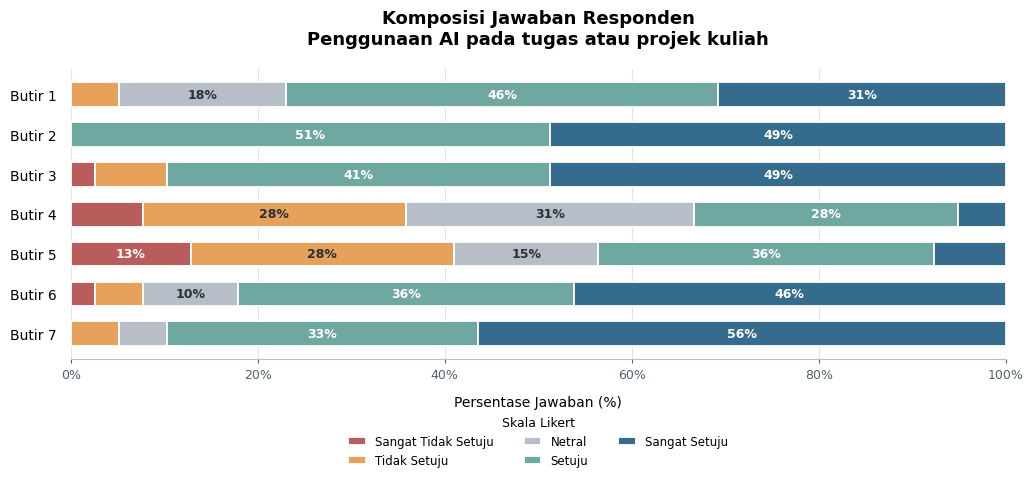

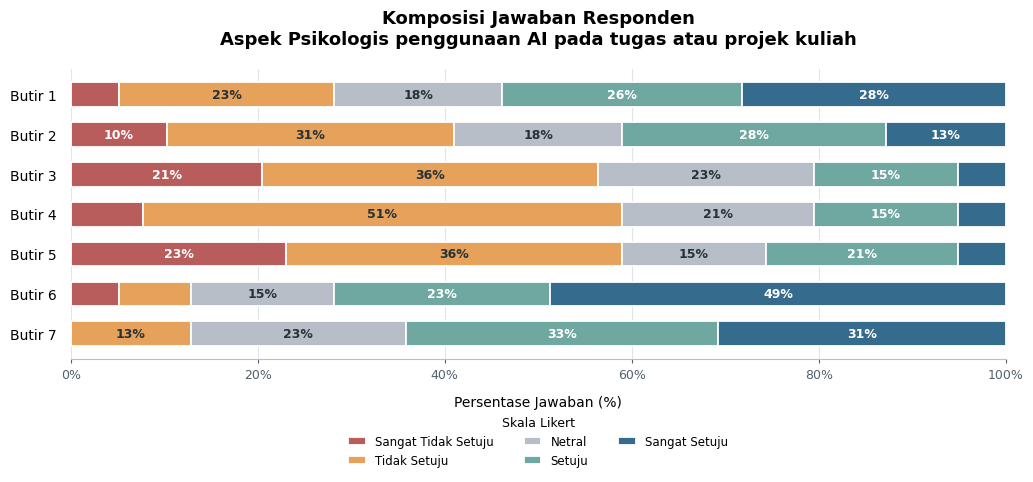

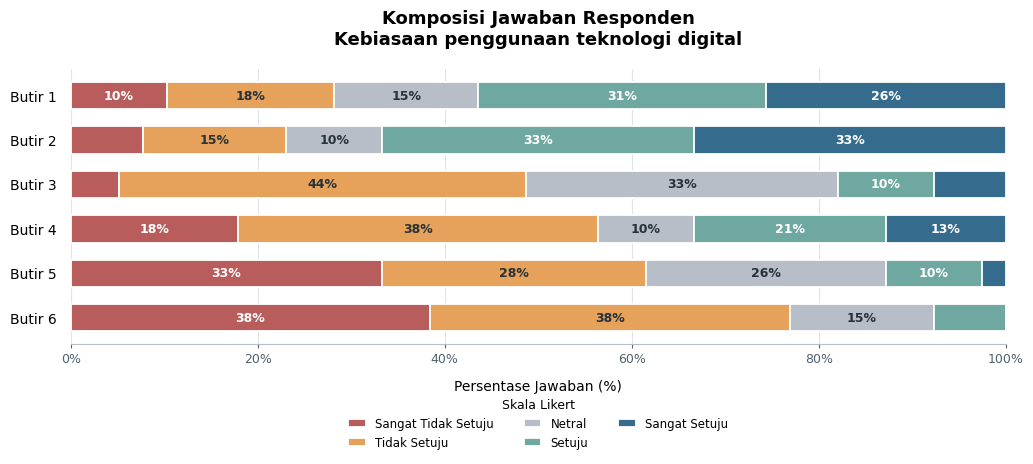

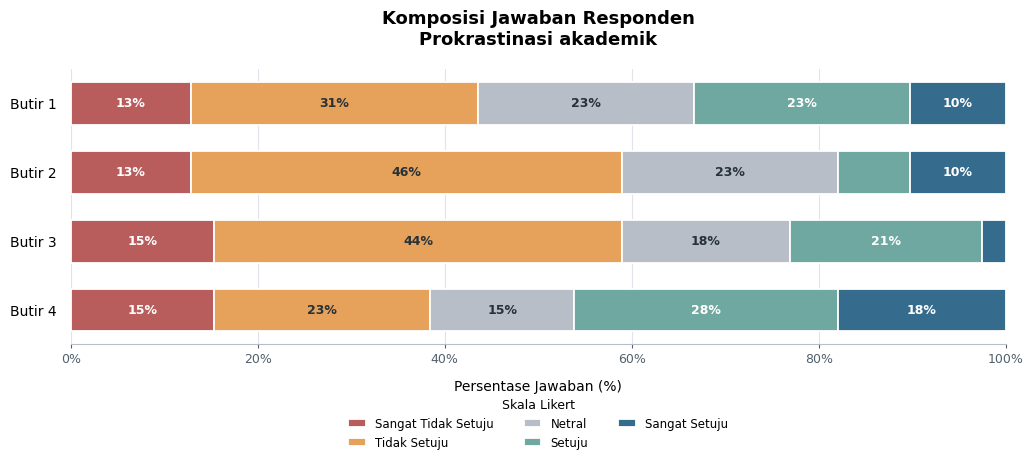

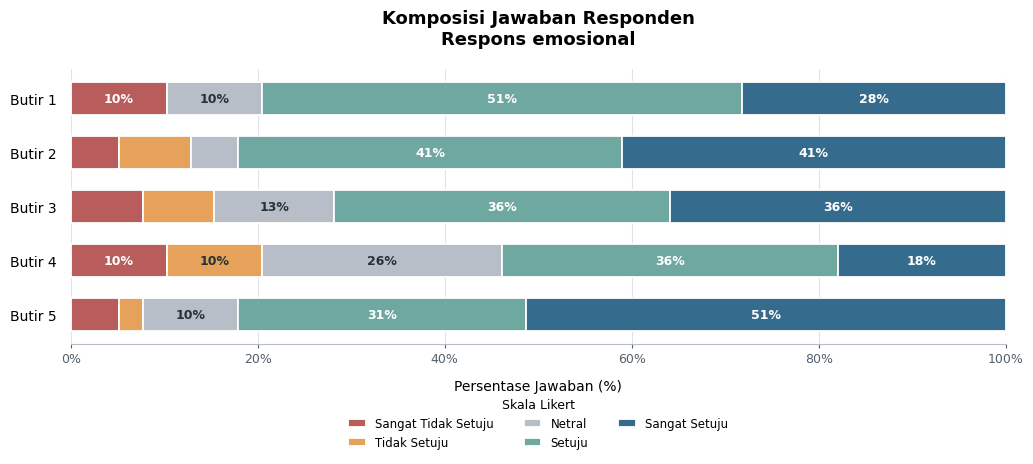

In [20]:

warna = {
    1: "#B85C5C",
    2: "#E6A15A",
    3: "#B8BEC7",
    4: "#6FA8A1",
    5: "#356B8C"
}

label_skala = {
    1: "Sangat Tidak Setuju",
    2: "Tidak Setuju",
    3: "Netral",
    4: "Setuju",
    5: "Sangat Setuju"
}

for nama, daftar in dimensi.items():
    data_dimensi = num[daftar]

    persentase = pd.DataFrame(
        {
            nilai: [
                (data_dimensi[kolom] == nilai).mean() * 100
                for kolom in daftar
            ]
            for nilai in range(1, 6)
        },
        index=[f"Butir {i}" for i in range(1, len(daftar) + 1)]
    )

    tinggi = max(4.5, len(daftar) * 0.68)

    fig, ax = plt.subplots(figsize=(11, tinggi))

    posisi = np.arange(len(persentase))
    kiri = np.zeros(len(persentase))

    for nilai in range(1, 6):
        bagian = persentase[nilai].to_numpy()

        ax.barh(
            posisi,
            bagian,
            left=kiri,
            height=0.62,
            color=warna[nilai],
            edgecolor="white",
            linewidth=1.3,
            label=label_skala[nilai]
        )

        for y, lebar, awal in zip(posisi, bagian, kiri):
            if lebar >= 8:
                warna_teks = (
                    "white" if nilai in (1, 4, 5)
                    else "#263238"
                )

                ax.text(
                    awal + lebar / 2,
                    y,
                    f"{lebar:.0f}%",
                    ha="center",
                    va="center",
                    fontsize=9,
                    color=warna_teks,
                    fontweight="bold"
                )

        kiri += bagian

    ax.set_yticks(posisi)
    ax.set_yticklabels(persentase.index, fontsize=10)
    ax.invert_yaxis()

    ax.set_xlim(0, 100)
    ax.set_xticks(np.arange(0, 101, 20))
    ax.set_xticklabels(
        [f"{x}%" for x in range(0, 101, 20)],
        fontsize=9
    )

    ax.set_xlabel(
        "Persentase Jawaban (%)",
        fontsize=10,
        labelpad=10
    )

    ax.set_title(
        f"Komposisi Jawaban Responden\n{nama}",
        fontsize=13,
        fontweight="bold",
        loc="center",
        pad=18
    )

    ax.grid(
        axis="x",
        color="#D9DEE5",
        linewidth=0.8,
        linestyle="-",
        alpha=0.8
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color("#B8BEC7")

    ax.tick_params(axis="y", length=0, pad=10)
    ax.tick_params(axis="x", colors="#52606D", length=3)

    ax.legend(
        ncol=3,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.16),
        frameon=False,
        fontsize=8.5,
        title="Skala Likert",
        title_fontsize=9,
        columnspacing=2.5,
        handlelength=1.5
    )

    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")

    plt.subplots_adjust(
        left=0.12,
        right=0.97,
        top=0.85,
        bottom=0.24
    )

    plt.show()


## 11. Grafik Statistik Deskriptif Antar Dimensi

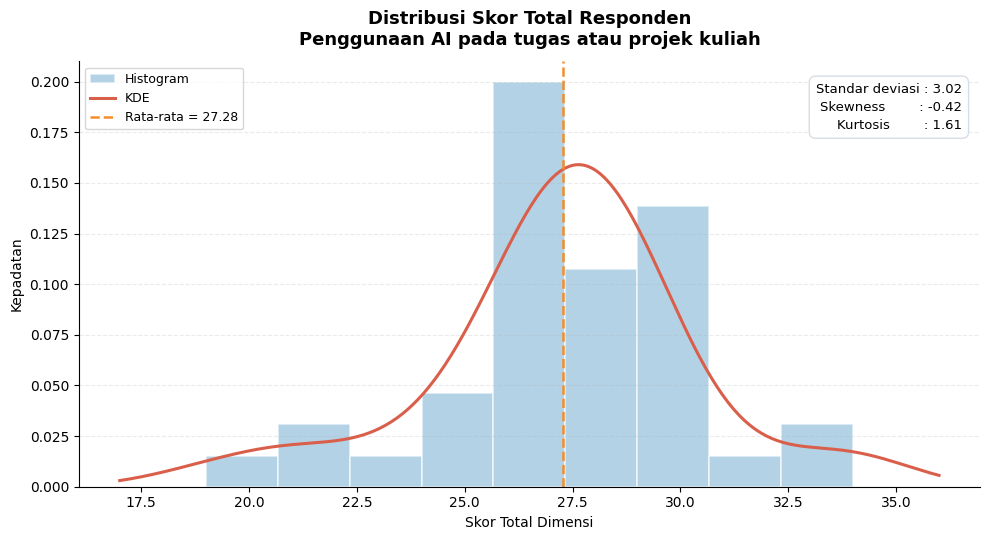

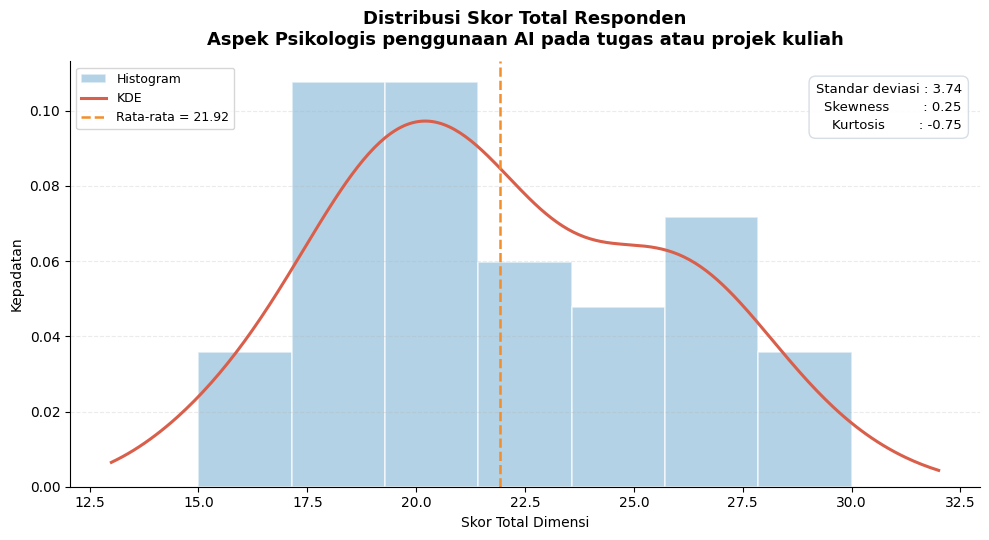

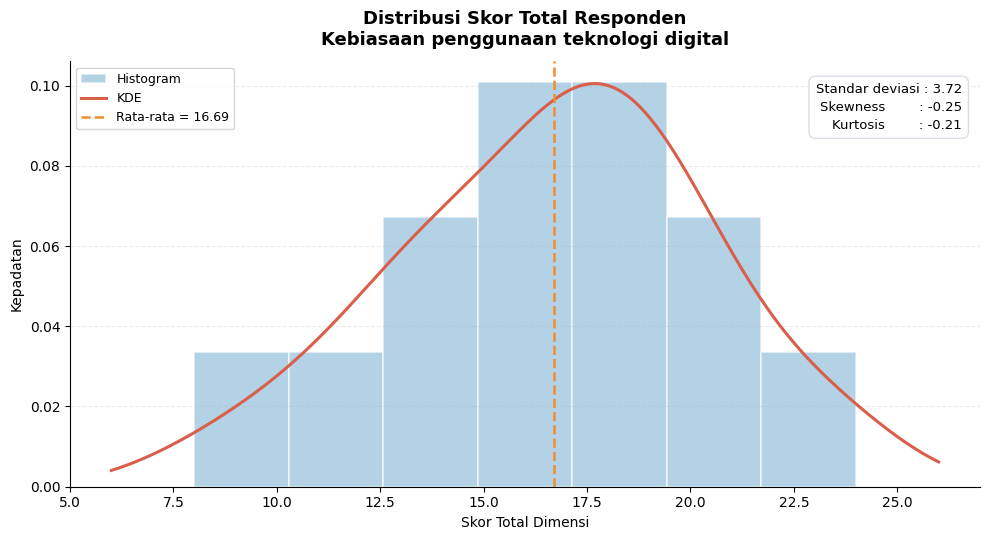

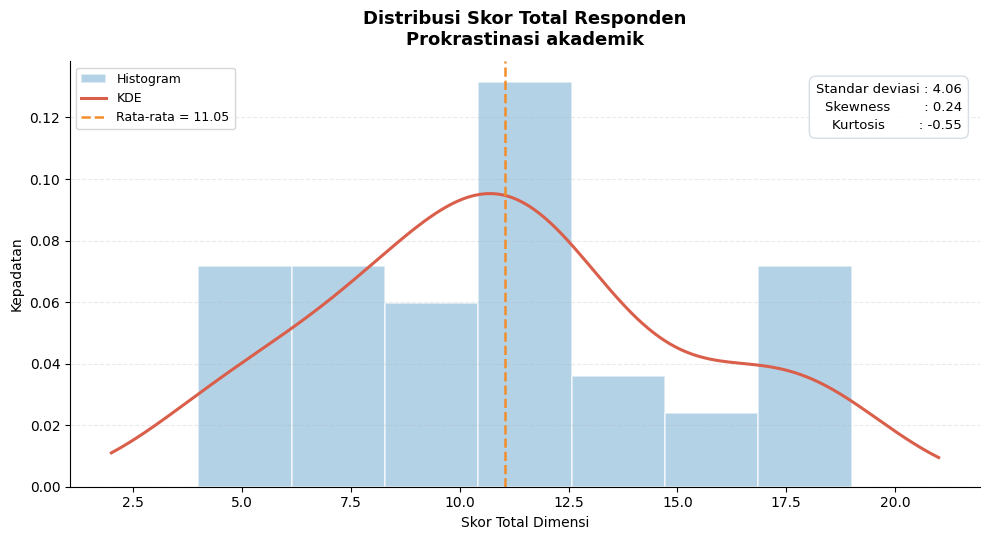

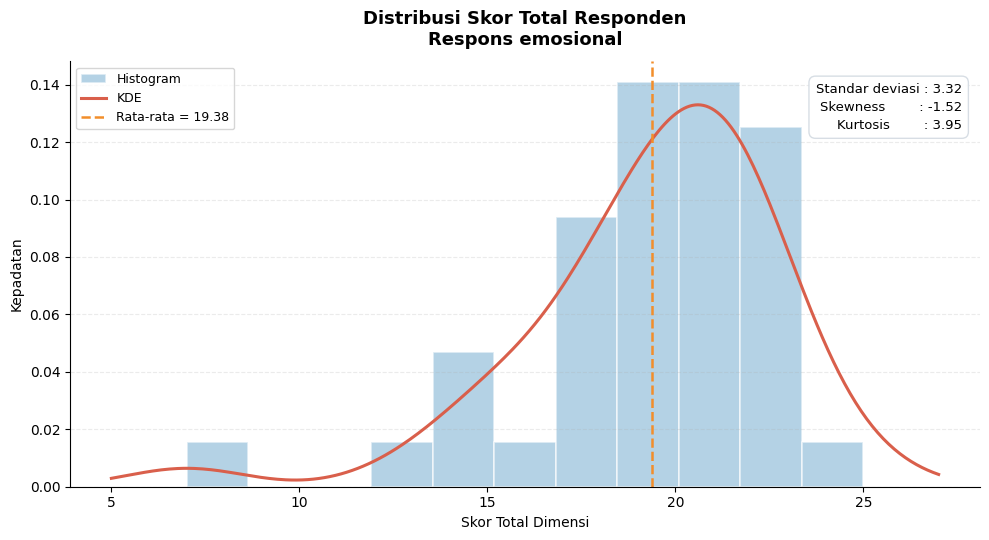

In [19]:

for nama, daftar in dimensi.items():
    skor_total = num[daftar].sum(axis=1)

    rata_rata = skor_total.mean()
    standar_deviasi = skor_total.std(ddof=1)
    skewness = stats.skew(skor_total, bias=False)
    kurtosis = stats.kurtosis(skor_total, fisher=True, bias=False)

    fig, ax = plt.subplots(figsize=(10, 5.5))

    ax.hist(
        skor_total,
        bins="auto",
        density=True,
        alpha=0.65,
        color="#8DBBD8",
        edgecolor="white",
        linewidth=1.2,
        label="Histogram"
    )

    if skor_total.nunique() > 1:
        x = np.linspace(skor_total.min() - 2, skor_total.max() + 2, 300)
        kde = stats.gaussian_kde(skor_total)
        ax.plot(
            x,
            kde(x),
            color="#D95F4B",
            linewidth=2.2,
            label="KDE"
        )

    ax.axvline(
        rata_rata,
        color="#F28E2B",
        linestyle="--",
        linewidth=1.8,
        label=f"Rata-rata = {rata_rata:.2f}"
    )

    ringkasan = (
        f"Standar deviasi : {standar_deviasi:.2f}\n"
        f"Skewness        : {skewness:.2f}\n"
        f"Kurtosis        : {kurtosis:.2f}"
    )

    ax.text(
        0.98, 0.95, ringkasan,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9.5,
        linespacing=1.5,
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white",
                  edgecolor="#D5DCE3", alpha=0.95)
    )

    ax.set_title(f"Distribusi Skor Total Responden\n{nama}", fontsize=13, weight="bold", pad=12)
    ax.set_xlabel("Skor Total Dimensi", fontsize=10)
    ax.set_ylabel("Kepadatan", fontsize=10)
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.legend(loc="upper left", frameon=True, fontsize=9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()


## 12. Latihan 1 — Interpretasi Butir Tidak Valid

In [12]:
butir_tidak_valid = tabel_validitas[tabel_validitas["Keterangan"] == "Tidak valid"]

print("Jumlah butir tidak valid:", len(butir_tidak_valid))
display(butir_tidak_valid[["Dimensi", "Butir", "r hitung", "Corrected r", "p-value"]])

Jumlah butir tidak valid: 5


,Dimensi,Butir,r hitung,Corrected r,p-value
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.269,0.105,0.0972
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.016,-0.247,0.9237
12,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B6,0.129,-0.191,0.4329
13,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B7,0.127,-0.146,0.4406
18,Kebiasaan penggunaan teknologi digital,B5,0.285,-0.013,0.0790


## 13. Latihan 2 — Perbandingan Kriteria Validitas

In [13]:
jumlah_valid_r = (tabel_validitas["r hitung"] > r_tabel).sum()
jumlah_valid_corrected = (tabel_validitas["Corrected r"] >= 0.30).sum()

print("Jumlah butir valid berdasarkan r hitung :", jumlah_valid_r)
print("Jumlah butir dengan corrected r ≥ 0,30 :", jumlah_valid_corrected)
print("Selisih jumlah butir:", abs(jumlah_valid_r - jumlah_valid_corrected))

Jumlah butir valid berdasarkan r hitung : 24
Jumlah butir dengan corrected r ≥ 0,30 : 13
Selisih jumlah butir: 11


## 14. Latihan 3 — Perbaikan Instrumen

In [14]:
kandidat = gabung[
    (gabung["Keterangan"] == "Tidak valid") &
    gabung["Alpha jika dihapus"].notna()
].copy()

if not kandidat.empty:
    kandidat["Perubahan alpha"] = kandidat.apply(
        lambda baris: baris["Alpha jika dihapus"] -
        tabel_reliabilitas.loc[
            tabel_reliabilitas["Dimensi"] == baris["Dimensi"],
            "Cronbach's alpha"
        ].iloc[0],
        axis=1
    )

    pilihan = kandidat.sort_values("Perubahan alpha", ascending=False).iloc[0]
    nama_pilihan = pilihan["Dimensi"]
    butir_pilihan = pilihan["Butir"]
    nomor_pilihan = int(butir_pilihan.replace("B", ""))
    kolom_pilihan = dimensi[nama_pilihan][nomor_pilihan - 1]

    data_awal = num[dimensi[nama_pilihan]]
    data_perbaikan = data_awal.drop(columns=kolom_pilihan)

    alpha_awal = cronbach_alpha(data_awal)
    alpha_baru = cronbach_alpha(data_perbaikan)

    print("Dimensi yang dievaluasi:", nama_pilihan)
    print("Butir yang dihapus:", butir_pilihan)
    print("Alpha sebelum penghapusan:", round(alpha_awal, 3))
    print("Alpha setelah penghapusan:", round(alpha_baru, 3))

    total_baru = data_perbaikan.sum(axis=1)
    hasil_perbaikan = []

    for i, kolom in enumerate(data_perbaikan.columns, 1):
        if data_perbaikan[kolom].nunique() <= 1 or total_baru.nunique() <= 1:
            r_baru = np.nan
        else:
            r_baru, _ = stats.pearsonr(data_perbaikan[kolom], total_baru)

        hasil_perbaikan.append({
            "Butir": f"B{i}",
            "r hitung setelah penghapusan": round(r_baru, 3) if pd.notna(r_baru) else np.nan,
            "Keterangan": "Valid" if pd.notna(r_baru) and r_baru > r_tabel else "Tidak valid"
        })

    display(pd.DataFrame(hasil_perbaikan))
else:
    print("Tidak terdapat butir tidak valid yang dapat dievaluasi.")

Dimensi yang dievaluasi: Aspek Psikologis penggunaan AI pada tugas atau projek kuliah
Butir yang dihapus: B6
Alpha sebelum penghapusan: 0.375
Alpha setelah penghapusan: 0.523


,Butir,r hitung setelah penghapusan,Keterangan
0,B1,0.601,Valid
1,B2,0.666,Valid
2,B3,0.597,Valid
3,B4,0.673,Valid
4,B5,0.639,Valid
5,B6,0.036,Tidak valid


## 15. Latihan 4 — Pengaruh Ukuran Sampel

In [15]:
num_subset = num.sample(n=min(20, len(num)), random_state=1)

n_subset = len(num_subset)
df_subset = n_subset - 2
t_subset = stats.t.ppf(0.975, df_subset)
r_tabel_subset = t_subset / np.sqrt(df_subset + t_subset**2)

hasil_subset = []

for nama, daftar in dimensi.items():
    x = num_subset[daftar]
    total = x.sum(axis=1)

    for i, kolom in enumerate(daftar, 1):
        if x[kolom].nunique() <= 1 or total.nunique() <= 1:
            r_subset = np.nan
        else:
            r_subset, _ = stats.pearsonr(x[kolom], total)

        hasil_subset.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "r hitung subset": round(r_subset, 3) if pd.notna(r_subset) else np.nan,
            "Keterangan": "Valid" if pd.notna(r_subset) and r_subset > r_tabel_subset else "Tidak valid"
        })

tabel_subset = pd.DataFrame(hasil_subset)

print("Jumlah sampel subset:", n_subset)
print(f"r tabel subset: {r_tabel_subset:.3f}")
display(tabel_subset)

Jumlah sampel subset: 20
r tabel subset: 0.444


,Dimensi,Butir,r hitung subset,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.496,Valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.096,Tidak valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.766,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.789,Valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.561,Valid
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.525,Valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,-0.098,Tidak valid
7,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B1,0.639,Valid
8,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B2,0.704,Valid
9,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B3,0.446,Valid
